# Ejercicio 5: Reconstrucción en condiciones ideales

In [27]:
import numpy as np
import matplotlib.pyplot as plt

In [28]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [29]:
x_fantoma = X_fantoma.reshape(-1)

In [30]:
def matriz_proyeccion(n, direcciones):
  res = []

  for direccion in direcciones:                                      # Por cada dirección (α, β)
    eses = []                                                        # Valores de s de esa dirección

    for i in range(n):                                               # Por cada fila
      for j in range(n):                                             # Por cada columna
        s = direccion[0] * i + direccion[1] * j                      # El s del rayo que pasa por ese píxel

        if s not in eses:                                            # Evitamos repetir rayos
          eses.append(s)

    for s in sorted(eses):                                           # Por cada rayo, de menor a mayor s
      res.append(mascara_rayo(n, direccion, s).reshape(-1))          # Agregamos su máscara vectorizada

  return np.array(res)

In [31]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

In [32]:
n=8
dir_2 = [(1,0), (0,1)]
dir_4 = [(1,0), (0,1), (1,1), (1,-1)]
dir_7 = [(1,0), (0,1), (1,1), (1,-1), (2,1), (1,2), (3,1)]

A_2 = matriz_proyeccion(n, dir_2)
A_4 = matriz_proyeccion(n, dir_4)
A_7 = matriz_proyeccion(n, dir_7)

a) Generamos, para cada *k* ∈ {2, 4, 7}, las mediciones *b<sub>k</sub>* = *A<sub>k</sub>* x<sub>fantoma</sub> y resolvemos el sistema mediante mínimos cuadrados con `np.linalg.lstsq` para obtener una reconstrucción *x̂<sub>k</sub>*







In [33]:
# Definimos las listas correspondientes
Ak = [A_2, A_4, A_7]
ks = [2, 4, 7]

# Listas para guardar las mediciones y las soluciones
bk = []
x_reconstruido = []

for A in Ak:
  # 1. Calculamos las mediciones b_k = A_k @ x_fantoma
  b_medida = A @ x_fantoma
  bk.append(b_medida)

  # 2. Resolvemos el sistema de mínimos cuadrados
  solucion, residuos, rango, singulares = np.linalg.lstsq(A, b_medida, rcond=None)
  x_reconstruido.append(solucion)

# Mostramos los tamaños obtenidos para verificar
for i, k in enumerate(ks):
  print(f"k = {k}: Dimensión de b_k = {bk[i].shape}, Dimensión de x_reconst = {x_reconstruido[i].shape}")

k = 2: Dimensión de b_k = (16,), Dimensión de x_reconst = (64,)
k = 4: Dimensión de b_k = (46,), Dimensión de x_reconst = (64,)
k = 7: Dimensión de b_k = (119,), Dimensión de x_reconst = (64,)


b) Calculamos el residuo r<sub>*k*</sub> = b<sub>*k*</sub> - *A<sub>k</sub>* *x̂<sub>k</sub>* y su norma. Calculamos también el error relativo ||*x̂<sub>k</sub>* - x<sub>fantoma</sub>|| / ||x<sub>fantoma</sub>||.

In [34]:
# Listas para guardar las mediciones
rk = []
norma_rk = []
err_relativo = []

for i in range(3):
  print()

  r = bk[i] - Ak[i] @ x_reconstruido[i]

  rk.append(r)
  norma_rk.append(np.linalg.norm(r))

  err_relativo.append(np.linalg.norm(x_reconstruido[i] - x_fantoma) / np.linalg.norm(x_fantoma))

print(f"norma_rk = {norma_rk}")
print(f"err_relativo = {err_relativo}")




norma_rk = [np.float64(3.3784647127668736e-15), np.float64(1.9284652119339846e-14), np.float64(1.395666440867215e-14)]
err_relativo = [np.float64(0.4689265478830206), np.float64(0.13646054073418715), np.float64(2.7538173565938914e-15)]


Resumimos en una tabla el rango de *A<sub>k</sub>*, la norma del residuo y el error relativo.

<table>
  <tr>
    <th>k</th>
    <th>rango(A<sub>k</sub>)*</th>
    <th>|| r<sub>k</sub> ||</th>
    <th>Error relativo</th>
  </tr>
  <tr>
    <td>2</td>
    <td>15</td>
    <td>3,3784647127668736e-15</td>
    <td>0,4689265478830206</td>
  </tr>
  <tr>
    <td>4</td>
    <td>39</td>
    <td>1,9284652119339846e-14</td>
    <td>0,13646054073418715</td>
  </tr>
  <tr>
    <td>7</td>
    <td>64</td>
    <td>1,395666440867215e-14</td>
    <td>2,7538173565938914e-15</td>
  </tr>
</table>

*Fuente: ejercicio 4 inciso (b).

c) Visualizamos, para cada caso, la imagen original, la reconstruccion y la diferencia entre ambas:

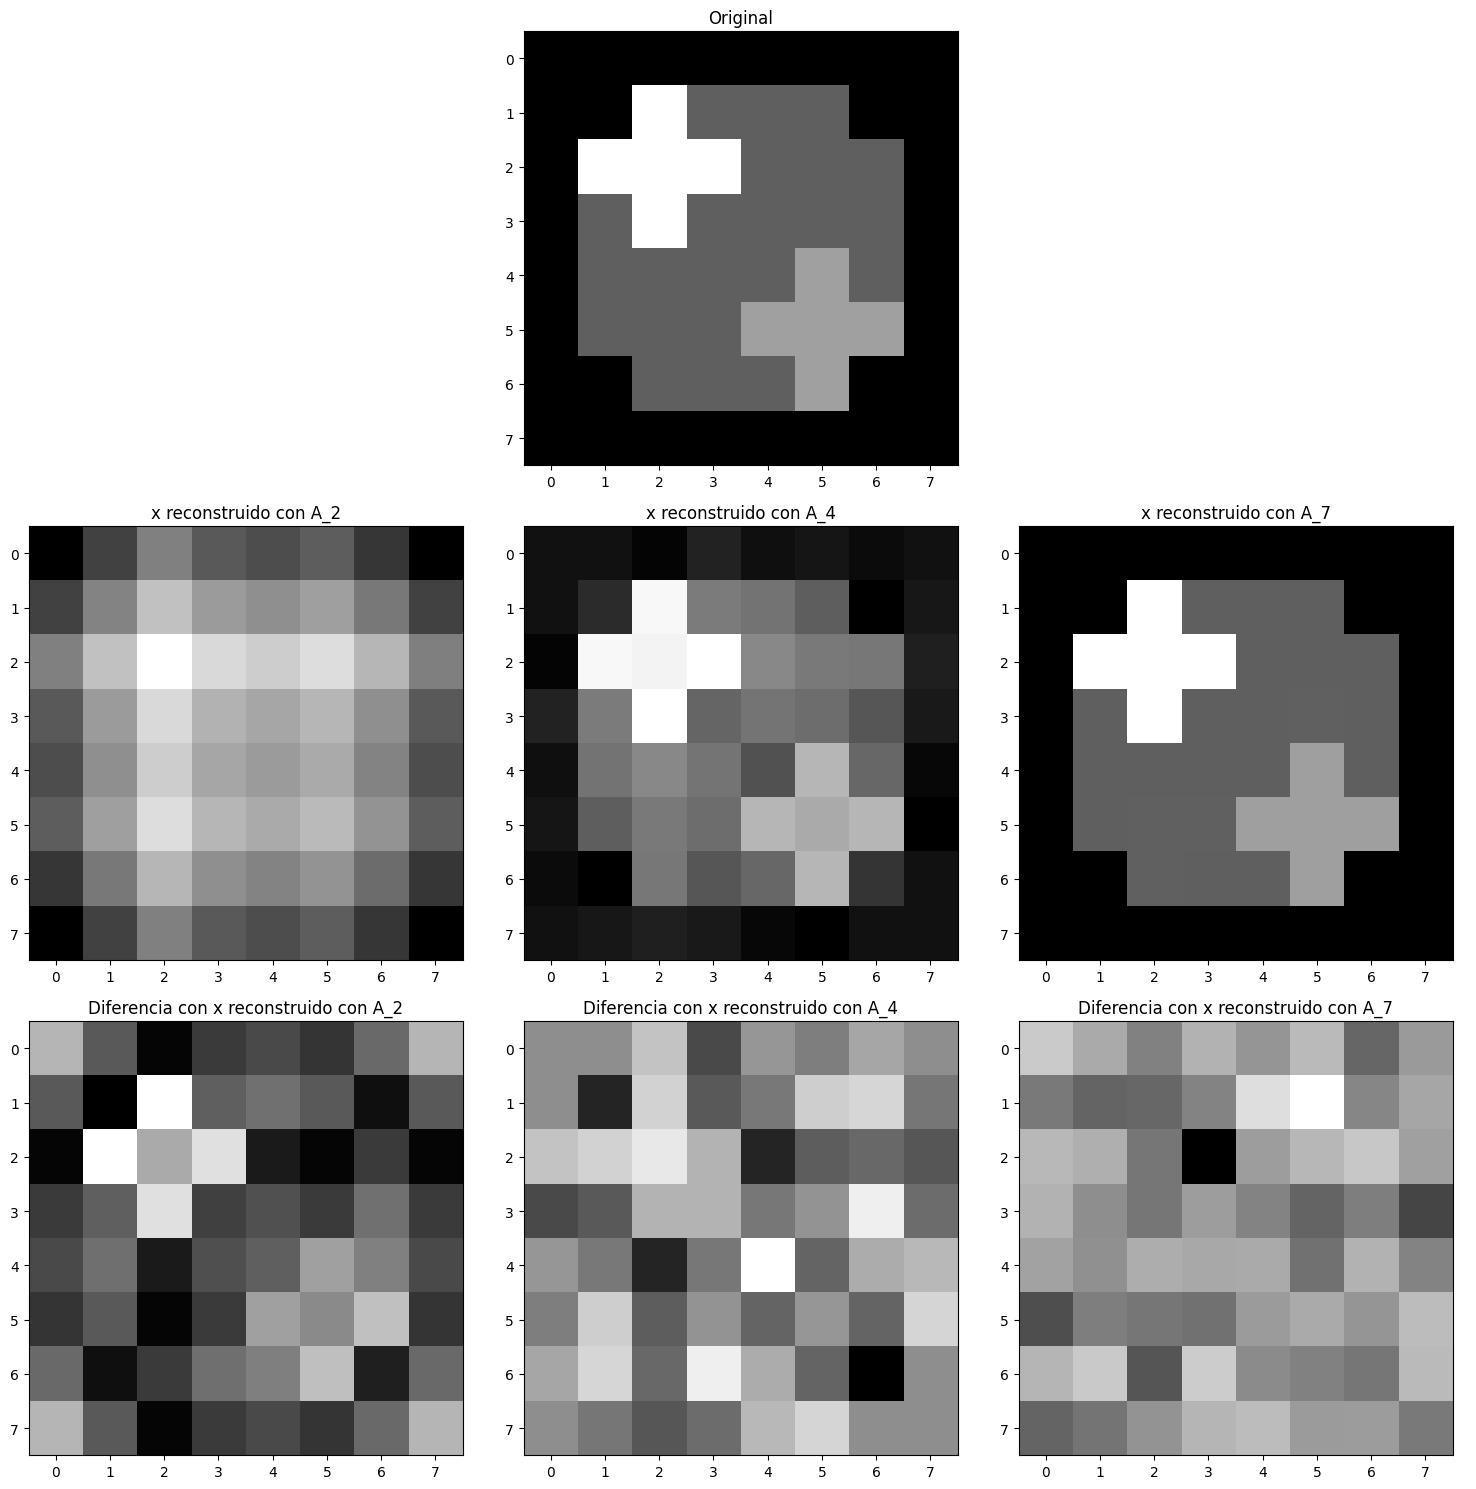

In [35]:
x_recon_matrix = []

# Convertimos los vectores a matrices
for x in x_reconstruido:
  x_recon_matrix.append(x.reshape(n, n))

fig, ax = plt.subplots(3, 3, figsize=(15, 15))

ax[0, 0].axis('off')

ax[0, 2].axis('off')

ax[0, 1].imshow(X_fantoma, cmap='gray')
ax[0, 1].set_title(f"Original")

ax[1, 0].imshow(x_recon_matrix[0], cmap='gray')
ax[1, 0].set_title(f"x reconstruido con A_2")

ax[1, 1].imshow(x_recon_matrix[1], cmap='gray')
ax[1, 1].set_title(f"x reconstruido con A_4")

ax[1, 2].imshow(x_recon_matrix[2], cmap='gray')
ax[1, 2].set_title(f"x reconstruido con A_7")

ax[2, 0].imshow(X_fantoma - x_recon_matrix[0], cmap='gray')
ax[2, 0].set_title(f"Diferencia con x reconstruido con A_2")

ax[2, 1].imshow(X_fantoma - x_recon_matrix[1], cmap='gray')
ax[2, 1].set_title(f"Diferencia con x reconstruido con A_4")

ax[2, 2].imshow(X_fantoma - x_recon_matrix[2], cmap='gray')
ax[2, 2].set_title(f"Diferencia con x reconstruido con A_7")

plt.tight_layout()
plt.show()

Un residuo cercano a cero no garantiza que la imagen original haya sido recuperada correctamente porque hay sistemas subdeterminados, es decir, hay más incógnitas que ecuaciones independientes (información).

Por el teorema de la dimensión, sabemos que el tamaño subespacio nulo de la matriz de proyección va a ser

$$64-\text{rango}(A_k)$$

Por eso, para los casos donde $\text{rango}(A_k) < 64$, existen infinitos vectores no nulos donde la solución es

$$A_k z = 0$$

Por lo tanto, para cualquier vector de la forma
$$\hat{x} = x_{\text{fantoma}} + z$$

va a generar exactamente las mismas mediciones:
$$b_k = A_k \hat{x} = A_k(x_{\text{fantoma}} + z) = A_k x_{\text{fantoma}} + 0 = b_k$$

Entonces, hay infinitos vectores que coinciden perfectamente con la aproximación (y dan residuo cero), pero no significa que hayan aproximado fiablemente a la imagen original.

**En resumen:**
La matriz de proyección representa el conjunto de trayectorias de los rayos X. Cuando el tamaño del subespacio nulo de la matriz completa es mayor a cero, significa que existen infinitas formas de alterar simultáneamente los valores de los píxeles (sumándoles un vector de distorsión $z$) sin alterar la suma final medida por **ninguno** de los rayos X. Esto genera una reconstrucción distorsionada que mantiene un residuo de cero, lo cual contradice el objetivo de recuperar fielmente la imagen original.